# Глубокий анализ признаков и статистические гипотезы

## Импорты

In [2]:
from pathlib import Path

In [3]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [4]:
from src.dataset import DatasetStore

In [5]:
import warnings
warnings.filterwarnings('ignore')

## Загрузка данных

In [6]:
df, schema = DatasetStore.load(
    "data/processed/dataset.csv",
    "data/processed/dataset.schema.json",
    include_missing=False,
)
feature_info = DatasetStore.get_feature_info(
    schema,
    include_missing=False,
)
target = "diagnosis"

y = LabelEncoder().fit_transform(df[target].values)
X = df.drop(columns=[target])

class_labels = [0, 1]

In [ ]:
RESULTS_PATH = Path('_reports/feature_target_associations.csv')
if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
else:
    raise FileNotFoundError('Сначала запустите 02_eda.ipynb, чтобы создать reports/feature_target_associations.csv')
results_df.head()

,feature,chi2,p_value,dof,cramers_v
0,meteorism,141.459236,1.916537e-31,2,0.597212
1,LS/cen gid,220.443965,3.102614e-43,8,0.521863
2,rigid of abdomi,197.185508,2.502506e-38,8,0.492466
3,Ur,85.574244,2.616912e-19,2,0.462313
4,LS steat,140.678448,2.020187e-29,4,0.418590


## 1. Ассоциации между признаками

In [9]:
def cramers_v_matrix(df, cols):
    n = len(cols)
    matrix = pd.DataFrame(np.eye(n), index=cols, columns=cols)
    for i in range(n):
        for j in range(i+1, n):
            ct = pd.crosstab(df[cols[i]], df[cols[j]])
            if ct.shape[0] < 2 or ct.shape[1] < 2:
                v = np.nan
            else:
                chi2 = stats.chi2_contingency(ct)[0]
                n_obs = ct.sum().sum()
                phi2 = chi2 / n_obs
                r, k = ct.shape
                phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n_obs-1))
                rcorr = r - ((r-1)**2)/(n_obs-1)
                kcorr = k - ((k-1)**2)/(n_obs-1)
                v = np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))
            matrix.iloc[i, j] = v
            matrix.iloc[j, i] = v
    return matrix

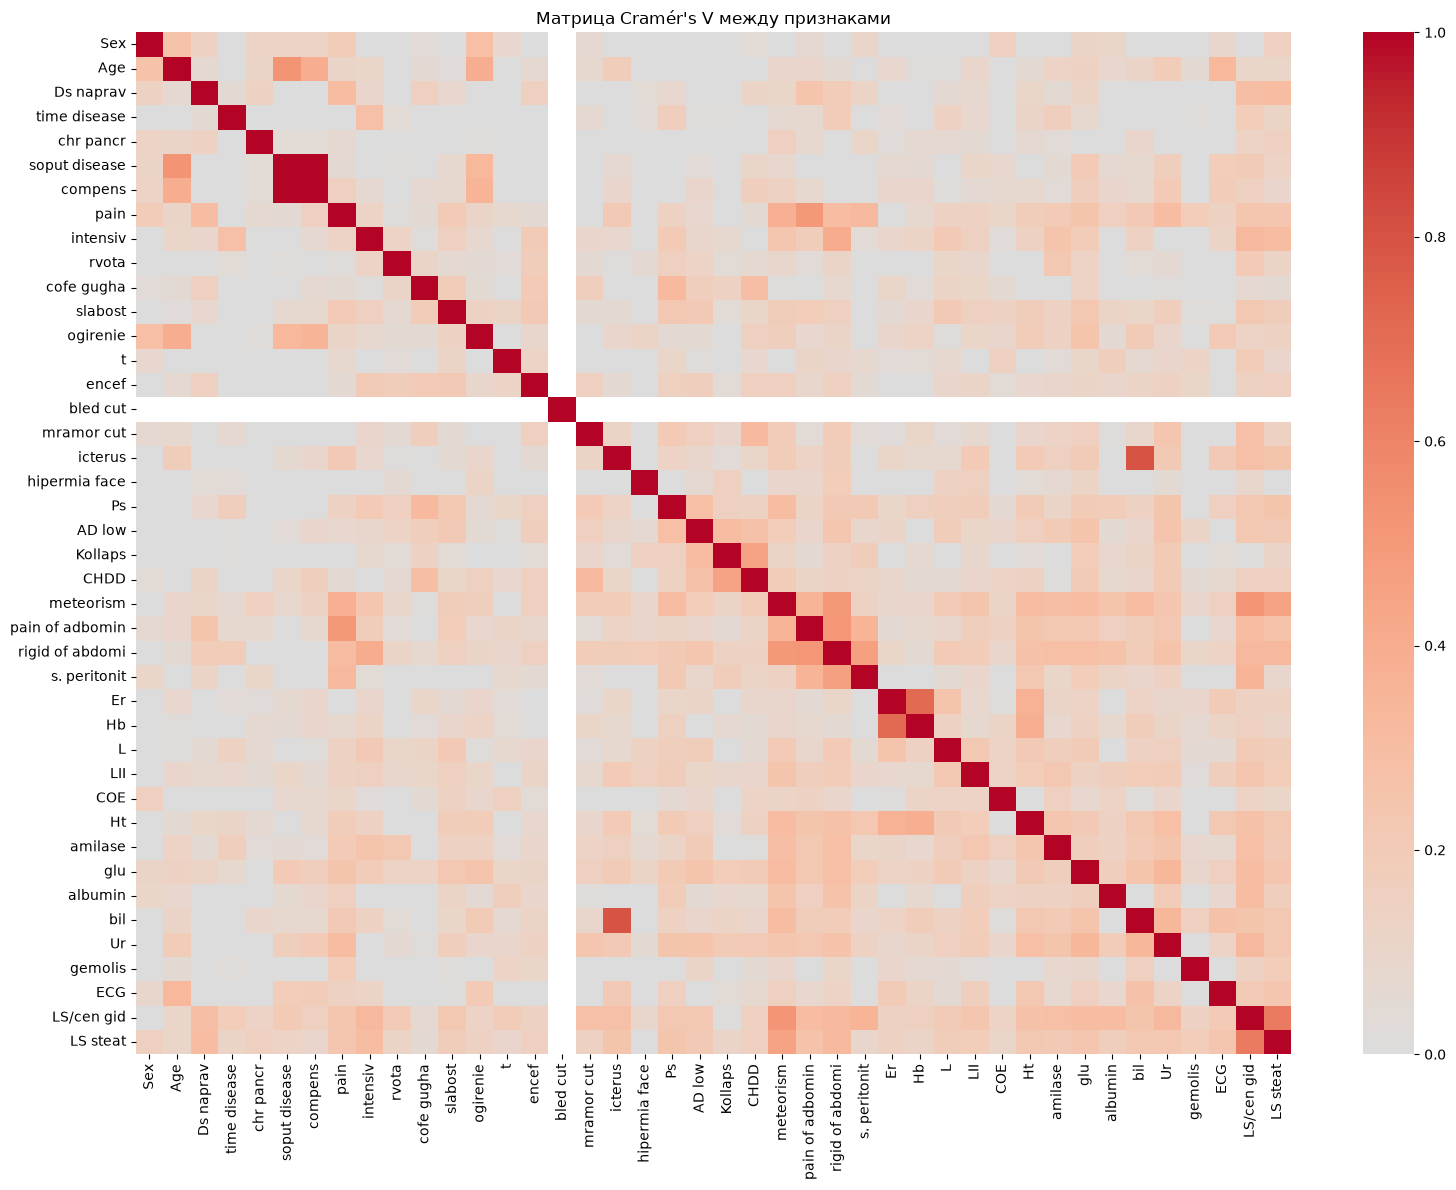

In [10]:
feature_cols = [c for c in df.columns if c != target]
assoc_matrix = cramers_v_matrix(df, feature_cols)

plt.figure(figsize=(16, 12))
sns.heatmap(assoc_matrix, cmap='coolwarm', center=0, vmin=0, vmax=1)
plt.title('Матрица Cramér\'s V между признаками')
plt.tight_layout()
plt.show()

In [11]:
pairs = []
for i in range(len(feature_cols)):
    for j in range(i+1, len(feature_cols)):
        v = assoc_matrix.iloc[i, j]
        if pd.notna(v) and v > 0.7:
            pairs.append({'feature_1': feature_cols[i], 'feature_2': feature_cols[j], 'cramers_v': v})
pairs_df = pd.DataFrame(pairs).sort_values('cramers_v', ascending=False)
display(pairs_df)
print(f'Пар с V > 0.7: {len(pairs_df)}')

,feature_1,feature_2,cramers_v
0,soput disease,compens,0.998717
1,icterus,bil,0.795578
2,Er,Hb,0.715449


Пар с V > 0.7: 3


## 2. Анализ ординальных признаков

['Age', 'time disease', 'chr pancr', 'intensiv', 'rvota', 'cofe gugha', 'slabost', 'Ps', 'CHDD', 'L', 'LII', 'COE', 'Ht', 'glu', 'albumin', 'bil']

=== Age ===


diagnosis,1,5,6
Age,,,
до 20 лет,0.600,0.400,0.000
21-30,0.742,0.226,0.032
31-40,0.622,0.204,0.173
41-50,0.581,0.267,0.151
51-60,0.717,0.130,0.152
старше 60 лет,0.478,0.211,0.311


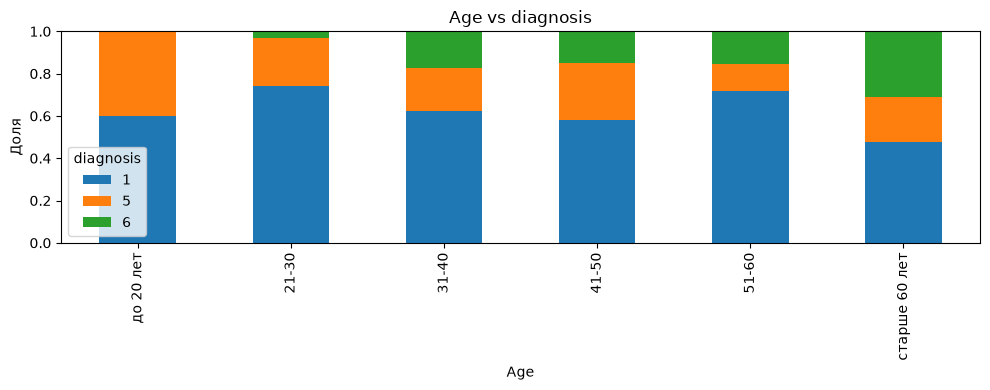


=== time disease ===


diagnosis,1,5,6
time disease,,,
более 24 часов,0.694,0.178,0.128
до 24 часов,0.538,0.255,0.208


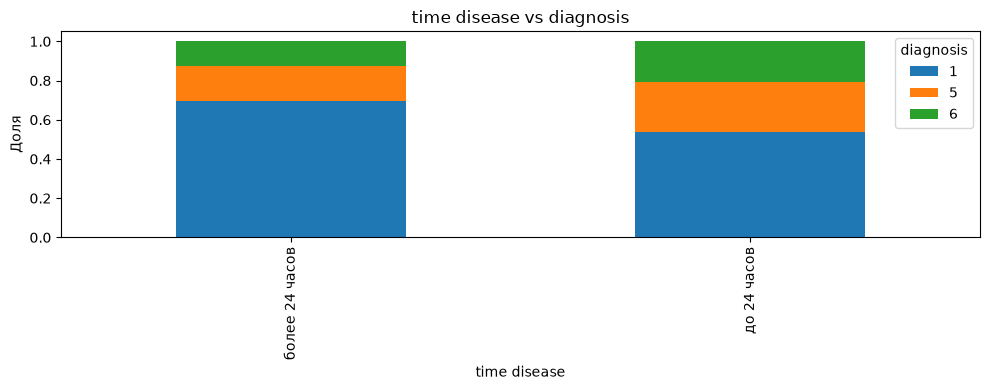


=== chr pancr ===


diagnosis,1,5,6
chr pancr,,,
есть,0.638,0.233,0.129
приступов не было,0.590,0.210,0.201


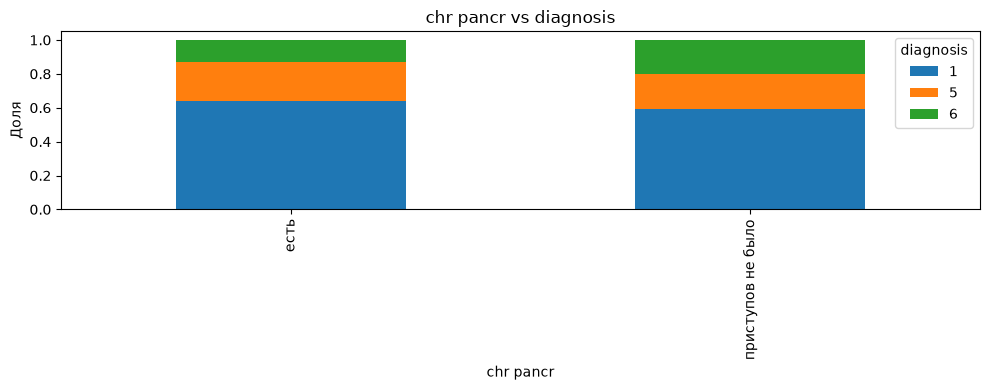


=== intensiv ===


diagnosis,1,5,6
intensiv,,,
умеренная,0.755,0.110,0.135
интенсивная,0.387,0.387,0.226


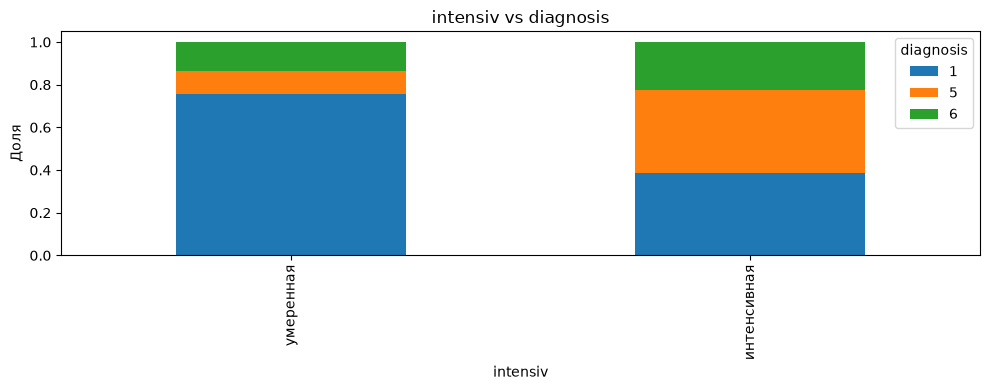


=== rvota ===


diagnosis,1,5,6
rvota,,,
не было,0.702,0.206,0.092
была,0.563,0.226,0.211


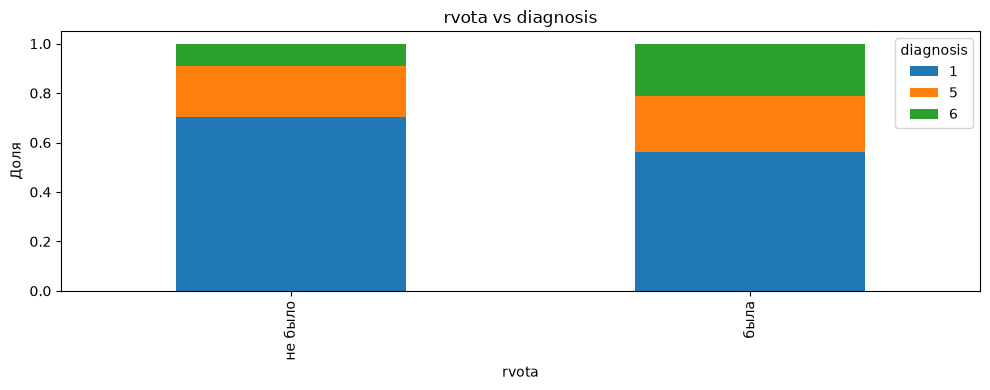


=== cofe gugha ===


diagnosis,1,5,6
cofe gugha,,,
не было,0.622,0.220,0.159
была,0.286,0.214,0.500


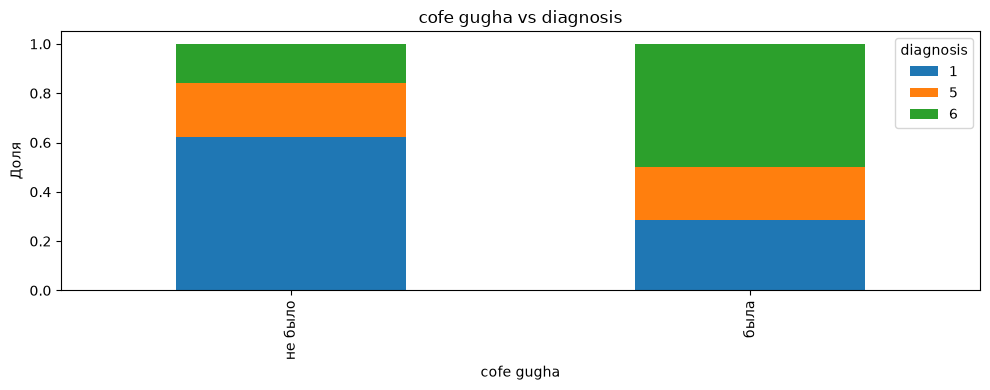


=== slabost ===


diagnosis,1,5,6
slabost,,,
не было,0.709,0.176,0.115
были,0.412,0.305,0.282


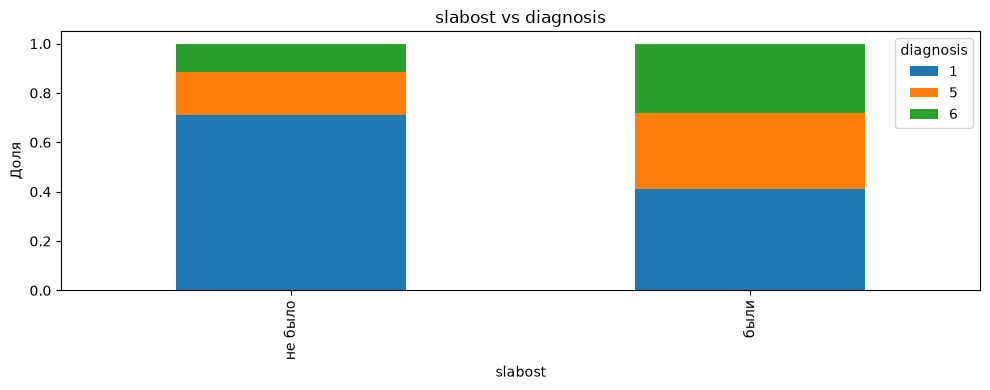


=== Ps ===


diagnosis,1,5,6
Ps,,,
менее 80,0.819,0.112,0.069
80-99,0.651,0.223,0.126
100-120,0.295,0.337,0.368
более 120,0.333,0.333,0.333


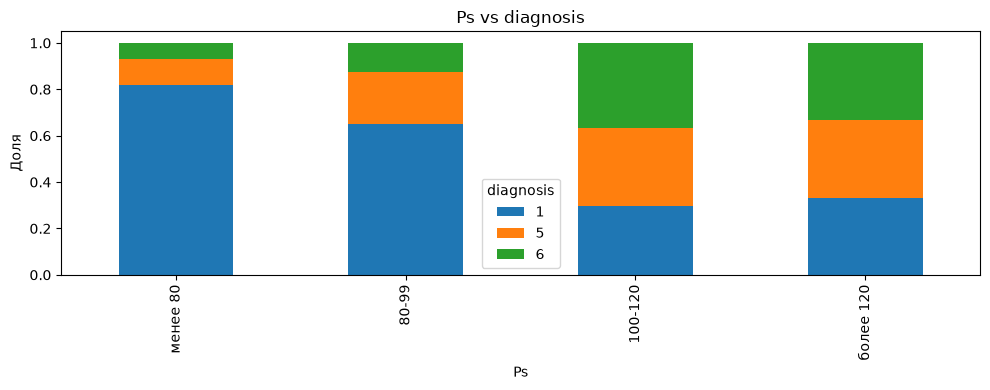


=== CHDD ===


diagnosis,1,5,6
CHDD,,,
16-20,0.639,0.215,0.147
21-26,0.235,0.353,0.412
более 26,0.000,0.143,0.857


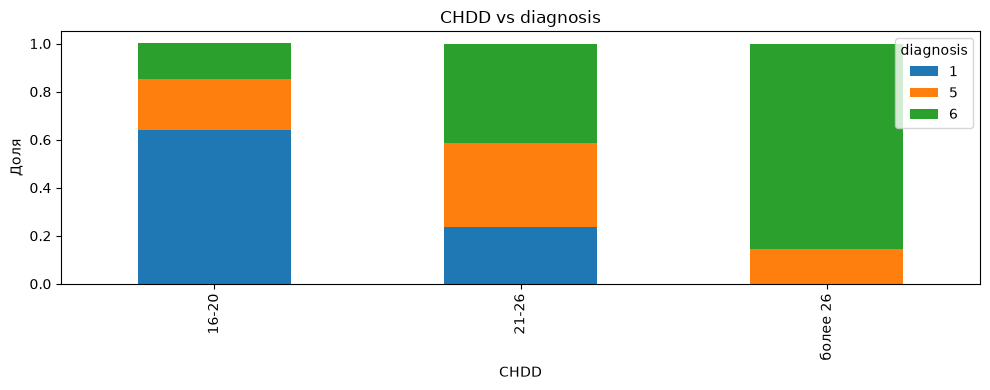


=== L ===


diagnosis,1,5,6
L,,,
норма (4-9*10^9/л),0.774,0.146,0.080
повышение до 14*10^9/л,0.489,0.298,0.214
выше 14*10^9/л,0.339,0.290,0.371


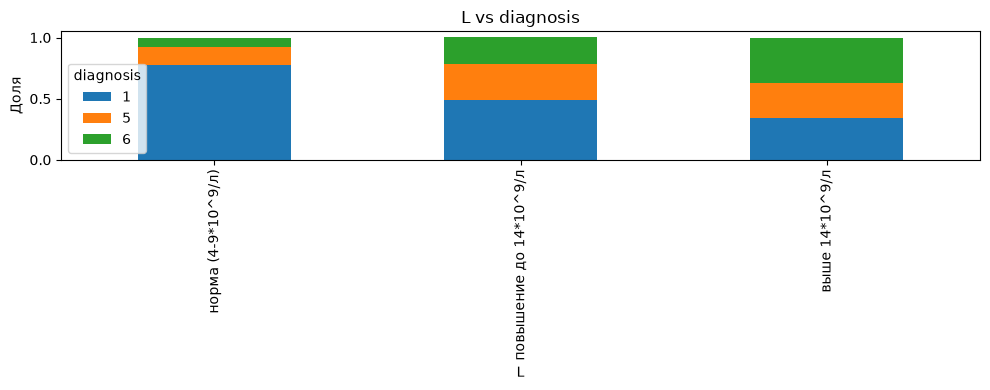


=== LII ===


diagnosis,1,5,6
LII,,,
"норма (0,3-1,5 ед.)",0.869,0.056,0.075
"1,6-2,9 ед.",0.727,0.195,0.078
"3,0 и более ед.",0.433,0.312,0.255


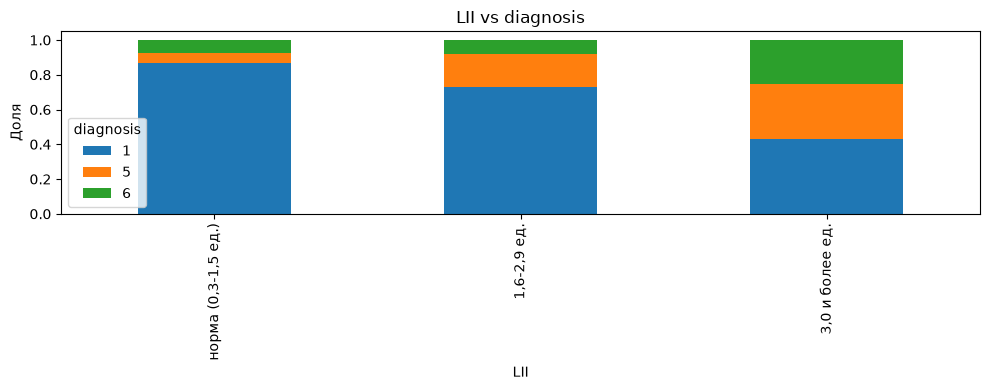


=== COE ===


diagnosis,1,5,6
COE,,,
норма (2-10 мм/ч),0.679,0.179,0.143
более 10 мм/ч,0.486,0.293,0.221


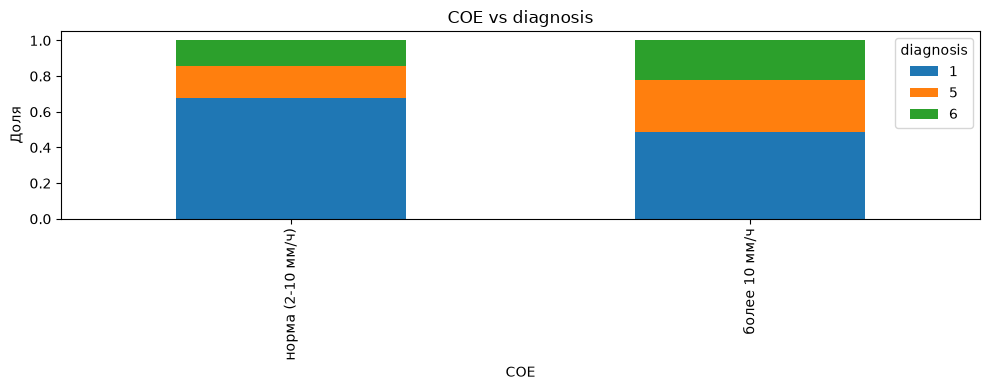


=== Ht ===


diagnosis,1,5,6
Ht,,,
ниже нормы (менее 42 %),0.785,0.139,0.077
норма (42-45 %),0.609,0.272,0.120
выше нормы (более 45 %),0.209,0.352,0.440


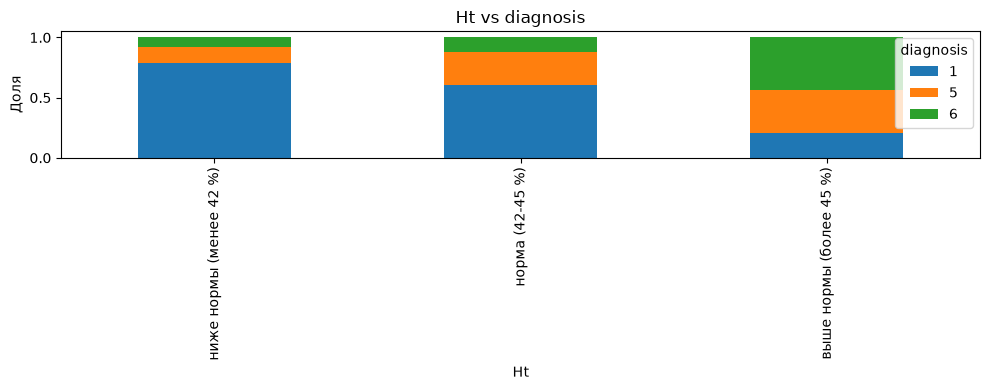


=== glu ===


diagnosis,1,5,6
glu,,,
"норма (3,3-5,5 ммоль/л)",0.787,0.154,0.059
"5,6-7,0 ммоль/л",0.426,0.377,0.197
"более 7,0 ммоль/л",0.169,0.312,0.519


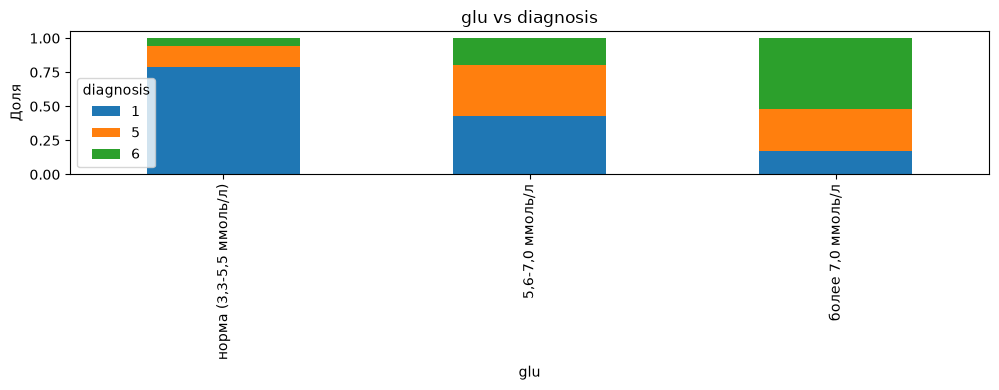


=== albumin ===


diagnosis,1,5,6
albumin,,,
"ниже нормы (60,0 и менее г/л)",0.684,0.186,0.131
"норма (60,1-80,0 г/л)",0.231,0.346,0.423


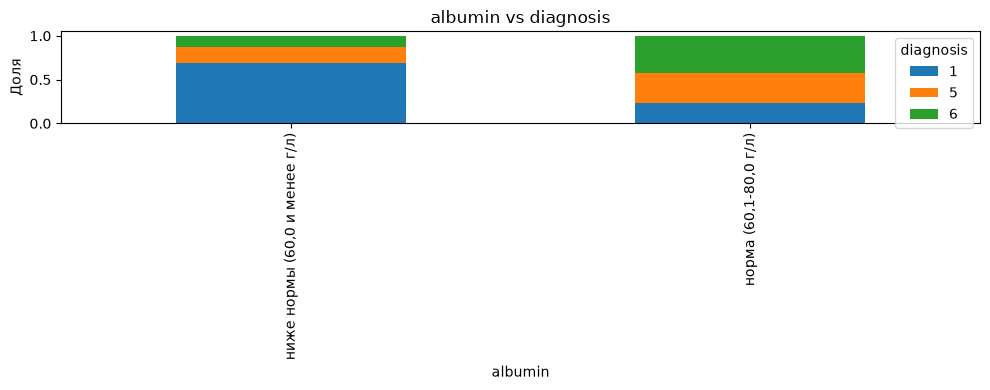


=== bil ===


diagnosis,1,5,6
bil,,,
"норма (до 20,5 ммоль/л)",0.721,0.187,0.092
"21,0-40,0 ммоль/л",0.327,0.288,0.385
"более 40,0 ммоль/л",0.217,0.348,0.435


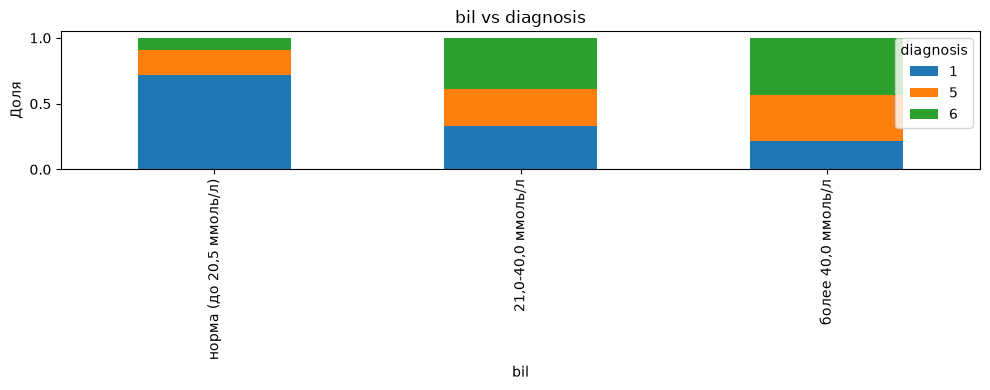

In [12]:
ordinal_cols = [col for col in df.columns if isinstance(df[col].dtype, pd.CategoricalDtype) and df[col].cat.ordered]
print(ordinal_cols)
for col in ordinal_cols:
    print(f'\n=== {col} ===')
    ct = pd.crosstab(df[col], df[target], normalize='index').round(3)
    display(ct)
    ct.plot(kind='bar', stacked=True, figsize=(10,4), title=f'{col} vs {target}')
    plt.ylabel('Доля')
    plt.tight_layout()
    plt.show()

## 3. Бинарные признаки и целевая переменная

In [13]:
binary_cols = []
for col in feature_cols:
    if df[col].nunique(dropna=True) == 2:
        binary_cols.append(col)

binary_results = []
for col in binary_cols:
    ct = pd.crosstab(df[col], df[target])
    if ct.shape[0] != 2:
        continue
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    row_totals = ct.sum(axis=1)
    props = ct.div(row_totals, axis=0)
    binary_results.append({
        'feature': col,
        'p_value': p,
        'chi2': chi2,
        'target_1_prop_diff': props.iloc[1].get(1, np.nan) - props.iloc[0].get(1, np.nan),
        'target_5_prop_diff': props.iloc[1].get(5, np.nan) - props.iloc[0].get(5, np.nan),
        'target_6_prop_diff': props.iloc[1].get(6, np.nan) - props.iloc[0].get(6, np.nan),
    })

binary_df = pd.DataFrame(binary_results).sort_values('p_value')
display(binary_df)

,feature,p_value,chi2,target_1_prop_diff,target_5_prop_diff,target_6_prop_diff
15,meteorism,1.916537e-31,141.459236,-0.586660,0.258033,0.328627
19,Ur,2.616912e-19,85.574244,-0.478292,0.001120,0.477172
5,intensiv,2.276614e-13,58.221834,-0.368177,0.277392,0.090785
16,s. peritonit,1.087843e-10,45.883307,-0.605072,0.121377,0.483696
11,icterus,2.407322e-10,44.294672,-0.484091,0.117614,0.366477
10,mramor cut,6.579143e-10,42.283893,-0.484409,-0.073118,0.557527
18,albumin,8.731251e-10,41.717884,-0.453080,0.160587,0.292493
8,slabost,5.240508e-08,33.528525,-0.296599,0.129098,0.167500
13,AD low,7.958522e-08,32.692875,-0.521937,0.287195,0.234742
14,Kollaps,3.817731e-07,29.556879,-0.619171,-0.222798,0.841969


## 4. Проверка гипотез: примеры

In [14]:
# Гипотеза 1: интенсивность боли связана с диагнозом
ct = pd.crosstab(df['intensiv'], df[target])
display(ct)
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f'Chi2 = {chi2:.3f}, p-value = {p:.4f}')

# Гипотеза 2: наличие рвоты связано с диагнозом
ct = pd.crosstab(df['rvota'], df[target])
display(ct)
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f'Chi2 = {chi2:.3f}, p-value = {p:.4f}')

diagnosis,1,5,6
intensiv,,,
умеренная,179,26,32
интенсивная,60,60,35


Chi2 = 58.222, p-value = 0.0000


diagnosis,1,5,6
rvota,,,
не было,92,27,12
была,147,59,55


Chi2 = 10.167, p-value = 0.0062


## 5. Поправка на множественные сравнения (Benjamini-Hochberg)

In [15]:
def benjamini_hochberg(p_values, alpha=0.05):
    p = np.asarray(p_values)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / (np.arange(1, n+1))
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.empty(n)
    out[order] = q
    return out

In [16]:
feature_target_p = results_df[['feature', 'p_value']].copy().dropna()
feature_target_p['p_adj'] = benjamini_hochberg(feature_target_p['p_value'])
feature_target_p = feature_target_p.sort_values('p_adj')
display(feature_target_p)

print('Значимые после FDR (p_adj < 0.05):')
display(feature_target_p[feature_target_p['p_adj'] < 0.05])

,feature,p_value,p_adj
1,LS/cen gid,3.102614e-43,1.241045e-41
2,rigid of abdomi,2.502506e-38,5.005011e-37
0,meteorism,1.916537e-31,2.555382e-30
4,LS steat,2.020187e-29,2.020187e-28
5,glu,4.837237e-27,3.869790e-26
7,pain of adbomin,6.370216e-21,4.246811e-20
8,Ht,1.076005e-20,6.148602e-20
10,amilase,2.005025e-19,1.002513e-18
3,Ur,2.616912e-19,1.163072e-18
9,pain,3.010785e-17,1.204314e-16


Значимые после FDR (p_adj < 0.05):


,feature,p_value,p_adj
1,LS/cen gid,3.102614e-43,1.241045e-41
2,rigid of abdomi,2.502506e-38,5.005011e-37
0,meteorism,1.916537e-31,2.555382e-30
4,LS steat,2.020187e-29,2.020187e-28
5,glu,4.837237e-27,3.869790e-26
7,pain of adbomin,6.370216e-21,4.246811e-20
8,Ht,1.076005e-20,6.148602e-20
10,amilase,2.005025e-19,1.002513e-18
3,Ur,2.616912e-19,1.163072e-18
9,pain,3.010785e-17,1.204314e-16


## 6. Итоговые выводы

In [ ]:
summary = results_df.merge(
    feature_target_p[['feature', 'p_adj']],
    on='feature',
    how='left'
).sort_values('cramers_v', ascending=False)
display(summary)

REPORT_DIR = Path('_reports')
REPORT_DIR.mkdir(exist_ok=True)
summary.to_csv(REPORT_DIR / 'feature_analysis_summary.csv', index=False)
binary_df.to_csv(REPORT_DIR / 'binary_feature_analysis.csv', index=False)
pairs_df.to_csv(REPORT_DIR / 'feature_pairs_high_association.csv', index=False)
print('Сохранено в', REPORT_DIR.resolve())

,feature,chi2,p_value,dof,cramers_v,p_adj
0,meteorism,141.459236,1.916537e-31,2,0.597212,2.555382e-30
1,LS/cen gid,220.443965,3.102614e-43,8,0.521863,1.241045e-41
2,rigid of abdomi,197.185508,2.502506e-38,8,0.492466,5.005011e-37
3,Ur,85.574244,2.616912e-19,2,0.462313,1.163072e-18
4,LS steat,140.678448,2.020187e-29,4,0.418590,2.020187e-28
5,glu,129.559532,4.837237e-27,4,0.401202,3.869790e-26
6,intensiv,58.221834,2.276614e-13,2,0.379180,7.588715e-13
7,pain of adbomin,107.635743,6.370216e-21,6,0.360949,4.246811e-20
8,Ht,99.816952,1.076005e-20,4,0.350472,6.148602e-20
9,pain,101.286904,3.010785e-17,10,0.342057,1.204314e-16


Сохранено в D:\Projects\OptimalMLMethod\reports
